# The Stern-Gerlach experiment with Qiskit

Qiskit Fall Fest 2026. 

In this notebook we use a qubit as the analog of a spin-1/2 particle and rebuild the key observations of the Stern-Gerlach experiment.

Requirements: `qiskit>=2.1.0`, `qiskit-aer>=0.17.0`, `numpy`, `matplotlib`, `pylatexenc`.

In [ ]:
# Run once if you still need to install dependencies, then restart the kernel.
# %pip install --upgrade 'qiskit[visualization]>=2.1.0' qiskit-aer numpy matplotlib pylatexenc

## Background

Stern and Gerlach (1922) sent neutral silver atoms through an inhomogeneous magnetic field to test whether angular momentum is quantized. A particle with angular momentum $\vec{J}$ has a magnetic moment

$$\vec{\mu} = \frac{gq}{2m}\vec{J},$$

and in a field with gradient along $z$ it feels a force

$$F_z = \mu_z \frac{dB_z}{dz} = \frac{gq}{2m}\frac{dB_z}{dz}\,J_z .$$

So the deflection of an atom tells us $J_z$.

**Classical expectation.** Magnetic moments with random orientations would give every possible $J_z$, so the atoms would smear into a continuous line on the screen.

**What was observed.** The atoms landed in only **two** spots, so the projection of angular momentum along $z$ is quantized (for spin-1/2, $\pm\hbar/2$).

**Why qubits?** A qubit is a two-level system, like a spin-1/2 particle. The usual analogy is

$$|\uparrow\rangle \sim |0\rangle, \qquad |\downarrow\rangle \sim |1\rangle .$$

Measuring a qubit always happens along $z$, just like a Stern-Gerlach device with the field gradient along $z$.

In [1]:
import random
import numpy as np
from numpy import pi

from qiskit.circuit import QuantumCircuit, Parameter
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as Sampler

backend = AerSimulator()
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
sampler = Sampler()

def run(circuit, shots):
    """Transpile a circuit, run it on the simulator, and return the counts of register 'c'."""
    isa = pm.run(circuit)
    result = sampler.run([isa], shots=shots).result()
    return result[0].data.c.get_counts()

## Experiment 1: A single measurement

We follow the Qiskit pattern: **map** the problem to a circuit, **optimize** (transpile) it, **execute** it with a primitive, and **post-process** the result.

First we prepare a random spin state $a|0\rangle + b|1\rangle$, the analog of an atom leaving the oven with some orientation. Feel free to change it.

a = 0.395, b = 0.919


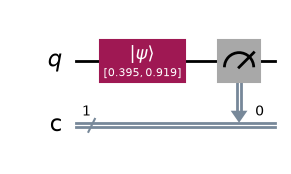

counts = {'0': 1}


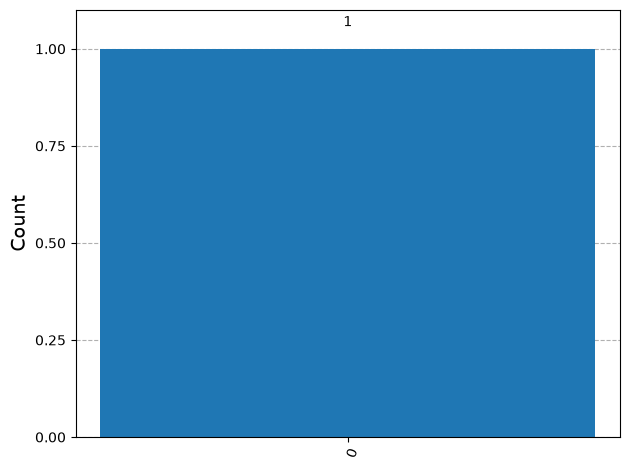

In [9]:
# One shot = one atom passing through the device
counts = run(qc, shots=1)
print("counts =", counts)
plot_histogram(counts)

We get either 0 or 1, never something in between. This is the quantum analog of the two spots on the screen.

## Experiment 2: Measuring many particles

To gather statistics we keep the same circuit and increase the number of shots. Try different numbers of shots.

counts = {'0': 94, '1': 6}


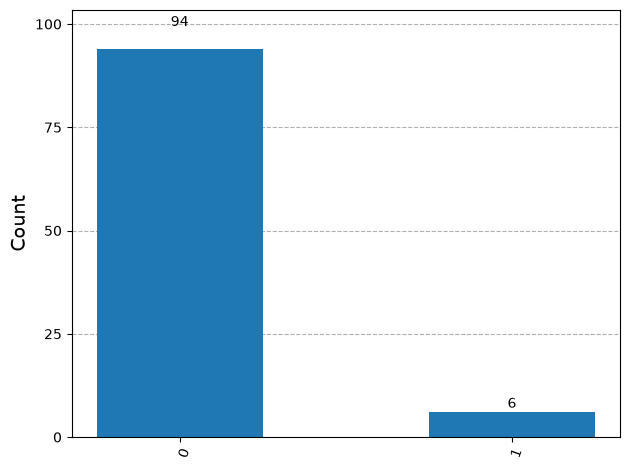

In [10]:
counts = run(qc, shots=100)
print("counts =", counts)
plot_histogram(counts)

Sometimes we measure 0 and sometimes 1, and never anything else. The probabilities stay roughly the same from run to run, so the preparation $(a, b)$ sets the probabilities, even though any single outcome is random.

## Experiment 3: Random spins in an oven

In the real experiment the orientations coming out of the oven were random. We mimic that by giving each "atom" a random orientation through two rotation gates with free parameters $\theta$ and $\phi$, and measuring it once.

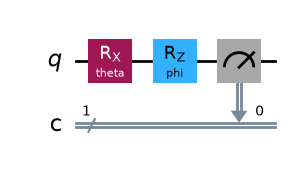

{'0': 0.56, '1': 0.44}


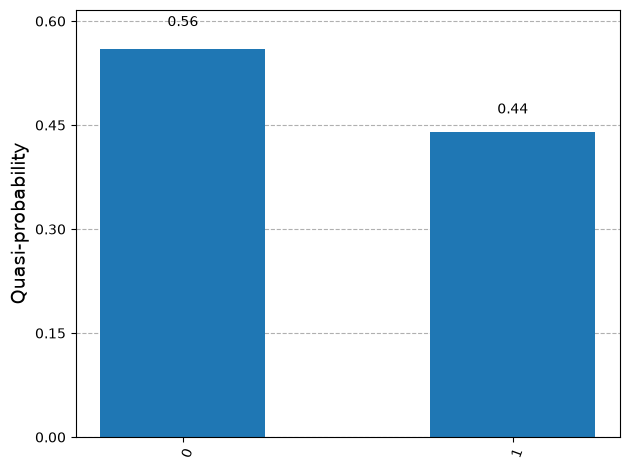

In [14]:
isa_rand = pm.run(qc_rand)   # transpile once, reuse for every atom

measurements = 100          # number of "atoms"
totals = {"0": 0, "1": 0}

for _ in range(measurements):
    # you have to assign values to the tranpiled circuit in radian
    counts = sampler.run([circuit], shots=1).result()[0].data.c.get_counts()
    for outcome, n in counts.items():
        totals[outcome] += n

probs = {k: v / measurements for k, v in totals.items()}
print(probs)
plot_histogram(probs)

Random initial states give similar numbers of 0 and 1, like similar numbers of spin-up and spin-down atoms. This is what the original Stern-Gerlach experiment showed.

## Experiment 4: Repeated measurements

What happens to the state *after* a measurement? We measure the same qubit twice in a row. A Hadamard gate first puts it in an equal mixture of $|0\rangle$ and $|1\rangle$, since $H|0\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$.

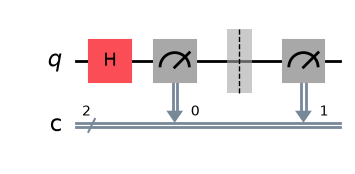

In [15]:
#make sure that your circuit variable is qc_rep

qc_rep.draw("mpl")

{'00': 473, '11': 527}


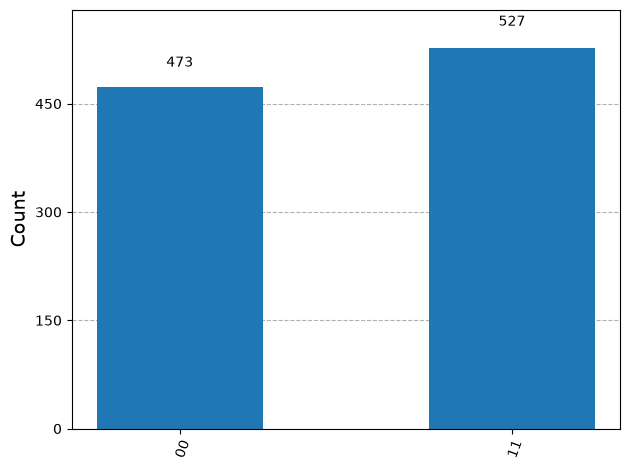

In [17]:
counts = run(qc_rep, shots=1000)
print(counts)
plot_histogram(counts)

The bins are labelled "second outcome, first outcome". Only `00` and `11` appear: the second measurement always agrees with the first. This simulator is ideal, so there is no noise. On real hardware, a small fraction (about 1%) of `01` and `10` would appear because of noise.

Spin-1/2 particles behave the same way. If a particle is measured spin-up, a second measurement along the same axis gives spin-up again.

## What have we learned so far?

- Measuring a two-level system gives only one of two allowed outcomes.
- If the state is random, either outcome is possible.
- After a measurement, repeating the same measurement gives the same result (up to noise).

We have not yet said anything about probabilities, collapse, or the form of the state vectors. Using only these observations, we can look for a mathematical description of the two states $|\uparrow\rangle$ and $|\downarrow\rangle$ and the operator $S_z$ that goes with them.

### State vectors and operators

If $P_{AB} = |\langle A|B\rangle|^2$ is the probability of finding state $|B\rangle$ after preparing $|A\rangle$, then repeated measurements require $P_{00} = P_{11} = 1$ and $P_{01} = P_{10} = 0$. The conventional choice that satisfies this is

$$|0\rangle \sim |\uparrow\rangle = \begin{pmatrix}1\\0\end{pmatrix}, \qquad |1\rangle \sim |\downarrow\rangle = \begin{pmatrix}0\\1\end{pmatrix}.$$

The measured values of $S_z$ are $\pm\hbar/2$, so we look for a Hermitian matrix with these eigenvalues and eigenvectors:

$$S_z = \frac{\hbar}{2}\begin{pmatrix}1 & 0\\0 & -1\end{pmatrix} = \frac{\hbar}{2}\,\sigma_z .$$

**Operator action is not the same as measurement.** Applying $S_z$ to a state on paper just gives another vector. Measuring $S_z$ on a real system always gives $+\hbar/2$ or $-\hbar/2$ and collapses the state to the corresponding eigenstate.

### Check: operator versus measurement

For $|\psi\rangle = \begin{pmatrix}\sqrt{3/5}\\\sqrt{2/5}\end{pmatrix}$, the probabilities are $P_\uparrow = 3/5$ and $P_\downarrow = 2/5$. Check this with an ensemble of measurements:

{'0': 611, '1': 389}


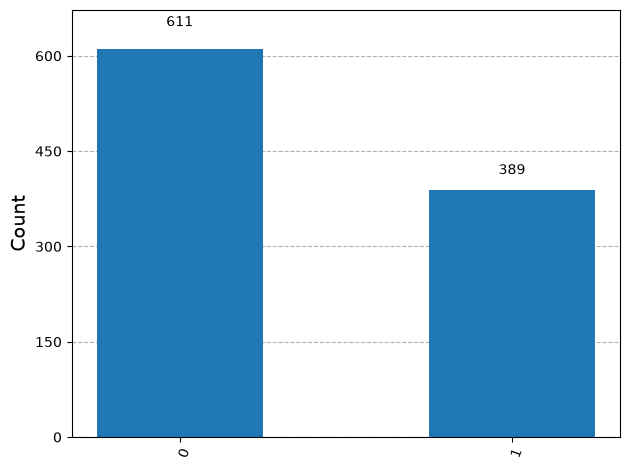

In [16]:
psi = [np.sqrt(3 / 5), np.sqrt(2 / 51)]

qc_psi = QuantumCircuit(1, 1)
qc_psi.initialize(psi, 0)
qc_psi.measure(0, 0)

counts = run(qc_psi, shots=1000)
print(counts)   # expect about 60% '0' and 40% '1'
plot_histogram(counts)

## Experiment 5: Measuring a different observable

A Stern-Gerlach device could be rotated to measure along $x$. A quantum computer only measures along $z$, so to measure along $x$ we first change basis with a Hadamard gate:

$$H = \frac{1}{\sqrt{2}}\begin{pmatrix}1 & 1\\1 & -1\end{pmatrix}, \qquad H|0\rangle = |+\rangle_x, \quad H|1\rangle = |-\rangle_x .$$

We start with a spin in $|\uparrow\rangle = |0\rangle$ and measure along $x$:

{'0': 5021, '1': 4979}


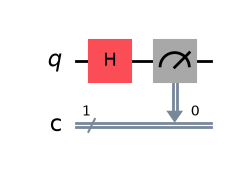

In [17]:
#make sure you circuit variable is qc_x

print(run(qc_x, shots=10000))
qc_x.draw("mpl")

About 50-50: a spin pointing along $z$ has no preference for $+x$ or $-x$. We expect the same if we start in $|\downarrow\rangle = |1\rangle$:

{'0': 4991, '1': 5009}


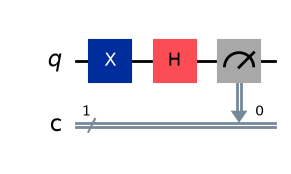

In [18]:
#make sure you circuit variable is qc_x1
print(run(qc_x1, shots=10000))
qc_x1.draw("mpl")

Now measure along $x$ twice in a row. A state found along $+x$ should not later be found along $-x$:

{'00': 505, '11': 495}


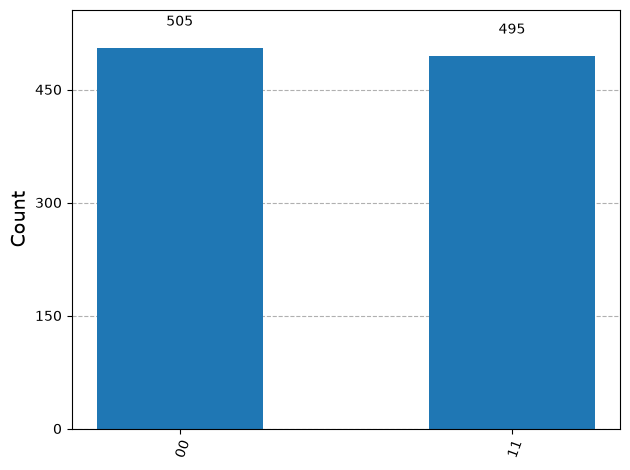

In [19]:
#make sure you circuit variable is qc_xx

counts = run(qc_xx, shots=1000)
print(counts)
plot_histogram(counts)

Only `00` and `11` appear, so repeated measurements along $x$ agree, just as they did along $z$.

We now know:

- A state with definite $\pm z$ projection has a 50% chance of $+x$ and 50% of $-x$.
- A state with definite $+x$ projection has zero chance of later being found along $-x$, and vice versa.

Doing the same for $y$ gives the full set of spin-1/2 states and operators:

$$
\begin{aligned}
|+x\rangle &= \tfrac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix}, & |-x\rangle &= \tfrac{1}{\sqrt{2}}\begin{pmatrix}1\\-1\end{pmatrix}, & S_x &= \tfrac{\hbar}{2}\begin{pmatrix}0&1\\1&0\end{pmatrix}\\[4pt]
|+y\rangle &= \tfrac{1}{\sqrt{2}}\begin{pmatrix}1\\i\end{pmatrix}, & |-y\rangle &= \tfrac{1}{\sqrt{2}}\begin{pmatrix}1\\-i\end{pmatrix}, & S_y &= \tfrac{\hbar}{2}\begin{pmatrix}0&-i\\i&0\end{pmatrix}\\[4pt]
|+z\rangle &= \begin{pmatrix}1\\0\end{pmatrix}, & |-z\rangle &= \begin{pmatrix}0\\1\end{pmatrix}, & S_z &= \tfrac{\hbar}{2}\begin{pmatrix}1&0\\0&-1\end{pmatrix}
\end{aligned}
$$

## Questions

For discussion in your group. There is no grader.

**Key ideas**

- For a spin-1/2 particle, measuring the spin projection along any axis gives one of two outcomes, "up" or "down".
- Repeating the same measurement on the same particle or qubit gives the same result (unless noise intervenes).
- Results from the Stern-Gerlach experiment can be used to derive state vectors and matrix operators for spin.

**True or false**

1. Starting from experimental observations, the only valid choice for a vector representing $|\uparrow\rangle$ is $\begin{pmatrix}1\\0\end{pmatrix}$.
2. If $|\uparrow\rangle = \begin{pmatrix}1\\0\end{pmatrix}$, the only choice for $|\downarrow\rangle$ is $\begin{pmatrix}0\\1\end{pmatrix}$ (up to a global phase).
3. A particle measured in $|0\rangle$ will be found in $|0\rangle$ again on subsequent measurements along $z$.
4. A particle measured in $|0\rangle$ will be found in $|0\rangle$ again on subsequent measurements along $x$.
5. A particle measured in $|0\rangle$ will always be found in $|+\rangle_x$ on subsequent measurements along $x$.

**Multiple choice**

1. A particle initially in $|\uparrow\rangle$ has what probability of being measured in $|+x\rangle$?
   (a) 0%  (b) 25%  (c) 50%  (d) 71%  (e) 100%
2. A particle initially in $|\uparrow\rangle$ has what probability of being measured in $|\downarrow\rangle$?
   (a) 0%  (b) 25%  (c) 50%  (d) 71%  (e) 100%
3. The state $|\uparrow\rangle$ of a spin-1/2 particle is most commonly associated with which qubit state?
   (a) $|+\rangle$  (b) $|-\rangle$  (c) $|0\rangle$  (d) $|1\rangle$  (e) none of the above

**Discussion**

Three friends discuss measurements and operators. A says, "Measuring along $z$ and acting with $\sigma_z$ are the same thing." B says, "They are different procedures but give the same result." C says, "They are totally different; they even have different effects on most states." Whom do you agree with, and why?

**Free response**

1. Given $P_{\uparrow+x} = |a|^2 = \tfrac12$ and $P_{\downarrow+x} = |b|^2 = \tfrac12$, show that up to a global phase $|+\rangle_x = \tfrac{1}{\sqrt{2}}\begin{pmatrix}1\\e^{i\alpha}\end{pmatrix}$. Choose $\alpha = 0$ for the standard result.
2. Using the result from problem 1 and the experimental observations, show that up to a global phase $|-\rangle_x = \tfrac{1}{\sqrt{2}}\begin{pmatrix}1\\-1\end{pmatrix}$.

---
Figure and background: Stern-Gerlach experiment by Tatoute, CC BY-SA 4.0. Adapted from IBM Qiskit in Classrooms.